# PINN на DeepXDE: прямая и обратная задачи

В ноутбуке разобраны два примера из репозитория [DeepXDE](https://github.com/lululxvi/deepxde/tree/master/examples):

| Задача | Файл | Что ищем |
|---|---|---|
| **Прямая** | `examples/pinn_forward/Burgers.py` | решение $u(x,t)$ уравнения Бюргерса при известных уравнении, начальном и граничных условиях |
| **Обратная** | `examples/pinn_inverse/diffusion_1d_inverse.py` | неизвестный коэффициент диффузии $C$ (и заодно решение $u$) по нескольким измерениям |

Бэкенд — **PyTorch**.

## 1. Как работает PINN

**PINN (Physics-Informed Neural Network)** — нейросеть $u_\theta(x,t)$, которая аппроксимирует решение дифференциального уравнения. Её учат не только (или вовсе не) на данных, а на самом **уравнении**.

Пусть задача имеет вид
$$\mathcal{N}[u](x,t) = 0 \ \text{в области},\qquad \mathcal{B}[u]=g \ \text{на границе},\qquad u(x,0)=u_0(x).$$

1. **Сеть.** Полносвязная сеть (FNN) принимает координаты $(x,t)$ и выдаёт число $u_\theta(x,t)$.
2. **Производные.** $u_t,\ u_x,\ u_{xx}$ вычисляются **автоматическим дифференцированием** по входам сети: точно, без конечных разностей и без сетки.
3. **Точки коллокации.** В области, на границе и в начальный момент случайно выбираются точки. Расчётная сетка не нужна.
4. **Функция потерь** — сумма среднеквадратичных невязок:
$$\mathcal{L}(\theta) = \underbrace{\tfrac{1}{N_f}\sum |\mathcal{N}[u_\theta](x_i,t_i)|^2}_{\text{уравнение (PDE)}} + \underbrace{\tfrac{1}{N_b}\sum |\mathcal{B}[u_\theta]-g|^2}_{\text{граница (BC)}} + \underbrace{\tfrac{1}{N_0}\sum |u_\theta(x_j,0)-u_0(x_j)|^2}_{\text{начальное условие (IC)}} \;\big[+\ \text{данные}\big]$$
5. **Обучение.** Минимизируем $\mathcal{L}$ по весам $\theta$: сначала Adam (грубая настройка), затем L-BFGS (точная донастройка квазиньютоновским методом).

**Обратная задача** отличается одним: неизвестные параметры уравнения (например, коэффициент $C$) объявляются **обучаемыми переменными** и оптимизируются вместе с весами сети. Чтобы параметр стал определимым, в потери добавляются измерения решения в нескольких точках.

### Как это устроено в DeepXDE
| Шаг | API |
|---|---|
| геометрия и время | `dde.geometry.Interval`, `TimeDomain`, `GeometryXTime` |
| уравнение | Python-функция `pde(x, y)` с `dde.grad.jacobian` / `dde.grad.hessian` |
| условия | `dde.icbc.DirichletBC`, `IC`, `PointSetBC` (наблюдения) |
| данные (точки коллокации) | `dde.data.TimePDE` |
| сеть | `dde.nn.FNN` |
| обучение | `dde.Model` → `compile` → `train` |
| неизвестный параметр | `dde.Variable` + `external_trainable_variables` |

In [1]:
import os
os.environ["DDE_BACKEND"] = "pytorch"   # выбираем бэкенд до импорта deepxde

import numpy as np
import matplotlib.pyplot as plt
import torch
import deepxde as dde

dde.config.set_random_seed(1234)        # воспроизводимость
DATASET = "burgers"                    # папка с эталонным решением Burgers.npz
print("DeepXDE", dde.__version__, "| torch", torch.__version__)

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


DeepXDE 1.15.0 | torch 2.12.0


---
## 2. Прямая задача: уравнение Бюргерса

$$u_t + u\,u_x = \nu\,u_{xx},\qquad \nu=\frac{0.01}{\pi},\qquad x\in[-1,1],\ t\in[0,0.99]$$

$$u(x,0) = -\sin(\pi x),\qquad u(-1,t)=u(1,t)=0.$$

Это модель вязкой жидкости. Из-за малой вязкости около $x=0$ к моменту $t\approx 0.4$ образуется очень крутой фронт (почти ударная волна). Это классический сложный тест для PINN. Для проверки используется эталонное численное решение `Burgers.npz`.

### 2.1 Невязка уравнения
`x` — тензор точек формы `(N, 2)`: столбец 0 — $x$, столбец 1 — $t$. `y` — выход сети $u$.
`jacobian(y, x, i=0, j=k)` даёт $\partial u/\partial x_k$, `hessian(..., i=0, j=0)` даёт $\partial^2 u/\partial x^2$.

In [2]:
def burgers_pde(x, y):
    dy_x = dde.grad.jacobian(y, x, i=0, j=0)    # u_x
    dy_t = dde.grad.jacobian(y, x, i=0, j=1)    # u_t
    dy_xx = dde.grad.hessian(y, x, i=0, j=0)    # u_xx
    return dy_t + y * dy_x - 0.01 / np.pi * dy_xx   # должно быть = 0

### 2.2 Область, условия и точки коллокации
* `on_boundary` / `on_initial` — флаги DeepXDE, по которым выбираются точки на границе и в начальный момент.
* `TimePDE` случайно сэмплирует 2540 точек внутри области, 80 на границе $x=\pm1$ и 160 при $t=0$.

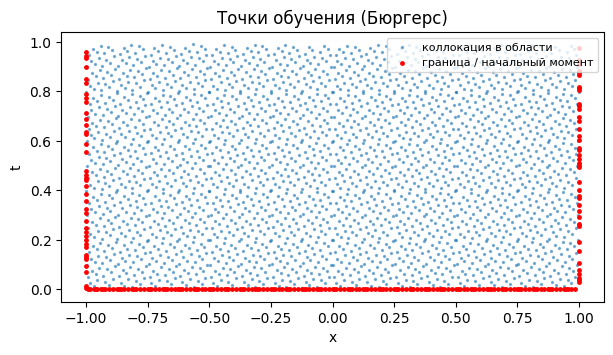

In [3]:
geom = dde.geometry.Interval(-1, 1)
timedomain = dde.geometry.TimeDomain(0, 0.99)
geomtime = dde.geometry.GeometryXTime(geom, timedomain)

bc = dde.icbc.DirichletBC(geomtime, lambda x: 0, lambda _, on_boundary: on_boundary)
ic = dde.icbc.IC(geomtime, lambda x: -np.sin(np.pi * x[:, 0:1]),
                 lambda _, on_initial: on_initial)

data_b = dde.data.TimePDE(geomtime, burgers_pde, [bc, ic],
                          num_domain=2540, num_boundary=80, num_initial=160)

fig, ax = plt.subplots(figsize=(7, 3.5))
pts = data_b.train_x_all
ax.scatter(pts[:, 0], pts[:, 1], s=2, alpha=0.5, label="коллокация в области")
ax.scatter(data_b.train_x_bc[:, 0], data_b.train_x_bc[:, 1], s=6, c="r", label="граница / начальный момент")
ax.set_xlabel("x"); ax.set_ylabel("t"); ax.set_title("Точки обучения (Бюргерс)")
ax.legend(loc="upper right", fontsize=8); plt.show()

### 2.3 Сеть и обучение
Сеть: вход 2 → 3 скрытых слоя по 20 нейронов (tanh) → выход 1. Гладкая `tanh` нужна потому, что потери содержат вторые производные сети.

Обучение идёт в два этапа: 15 000 итераций Adam (lr = 1e-3), затем L-BFGS до сходимости. В логе три столбца потерь: **[PDE, BC, IC]**.

In [4]:
net_b = dde.nn.FNN([2] + [20] * 3 + [1], "tanh", "Glorot normal")
model_b = dde.Model(data_b, net_b)

model_b.compile("adam", lr=1e-3)
model_b.train(iterations=15000, display_every=1000)
model_b.compile("L-BFGS")
loss_b, state_b = model_b.train(display_every=1000)

Compiling model...
'compile' took 0.000139 s



Training model...

Step      Train loss                        Test loss                         Test metric


0         [2.03e-02, 3.72e-03, 4.77e-01]    [2.03e-02, 3.72e-03, 4.77e-01]    []  


1000      [3.67e-02, 4.83e-04, 5.03e-02]    [3.67e-02, 4.83e-04, 5.03e-02]    []  


2000      [1.80e-02, 1.01e-04, 1.87e-02]    [1.80e-02, 1.01e-04, 1.87e-02]    []  


...

21000     [1.01e-05, 8.43e-08, 2.02e-06]    [1.01e-05, 8.43e-08, 2.02e-06]    []  


22000     [7.58e-06, 2.75e-08, 1.14e-06]    [7.58e-06, 2.75e-08, 1.14e-06]    []  


23000     [6.11e-06, 2.43e-08, 7.27e-07]    [6.11e-06, 2.43e-08, 7.27e-07]    []  


23012     [6.10e-06, 2.44e-08, 7.23e-07]    [6.10e-06, 2.44e-08, 7.23e-07]    []  



Best model at step 23012:
  train loss: 6.85e-06
  test loss: 6.85e-06
  test metric: []

'train' took 406.990217 s



### 2.4 Результаты
Сравниваем с эталоном на сетке $256\times100$. Метрика — относительная $L_2$-ошибка $\|u_\theta-u\|_2/\|u\|_2$.

In [5]:
d = np.load(f"{DATASET}/Burgers.npz")
t, x, exact = d["t"], d["x"], d["usol"].T          # exact: (nt, nx)
xx, tt = np.meshgrid(x, t)
X = np.vstack((xx.ravel(), tt.ravel())).T
u_true = exact.ravel()[:, None]

u_pred = model_b.predict(X)
residual = model_b.predict(X, operator=burgers_pde)
print("Средняя |невязка PDE|:", np.mean(np.abs(residual)))
print("Относительная L2-ошибка:", dde.metrics.l2_relative_error(u_true, u_pred))

Средняя |невязка PDE|: 0.0028031296
Относительная L2-ошибка: 0.004343982717139417


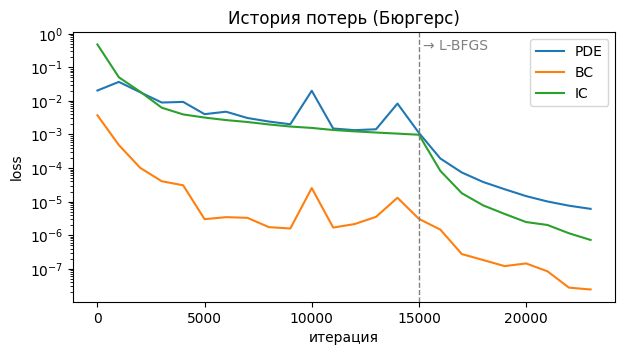

In [6]:
steps = np.array(loss_b.steps)
lt = np.array(loss_b.loss_train)
fig, ax = plt.subplots(figsize=(7, 3.5))
for k, name in enumerate(["PDE", "BC", "IC"]):
    ax.semilogy(steps, lt[:, k], label=name)
ax.axvline(15000, color="gray", ls="--", lw=1); ax.text(15200, ax.get_ylim()[1] * 0.3, "→ L-BFGS", color="gray")
ax.set_xlabel("итерация"); ax.set_ylabel("loss"); ax.set_title("История потерь (Бюргерс)"); ax.legend()
plt.show()

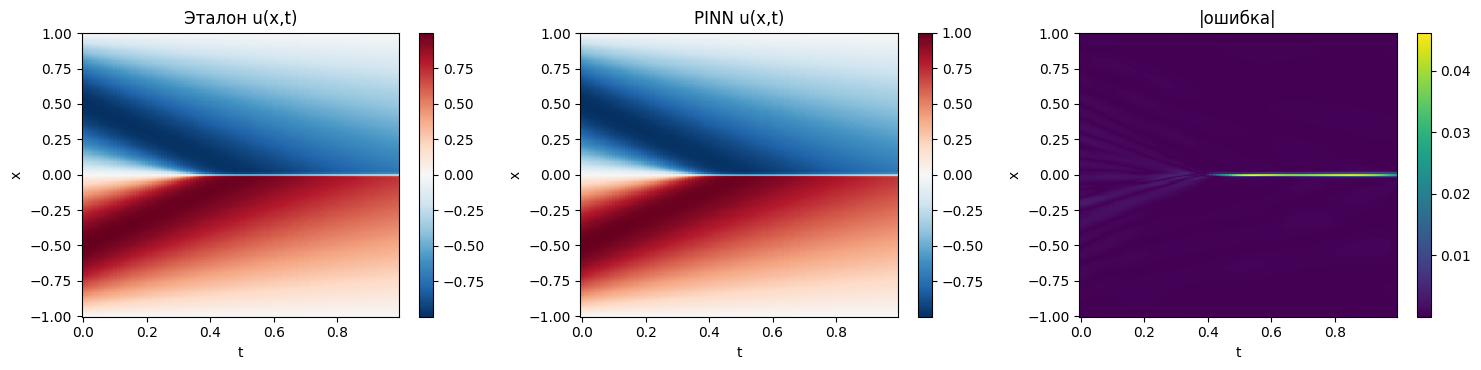

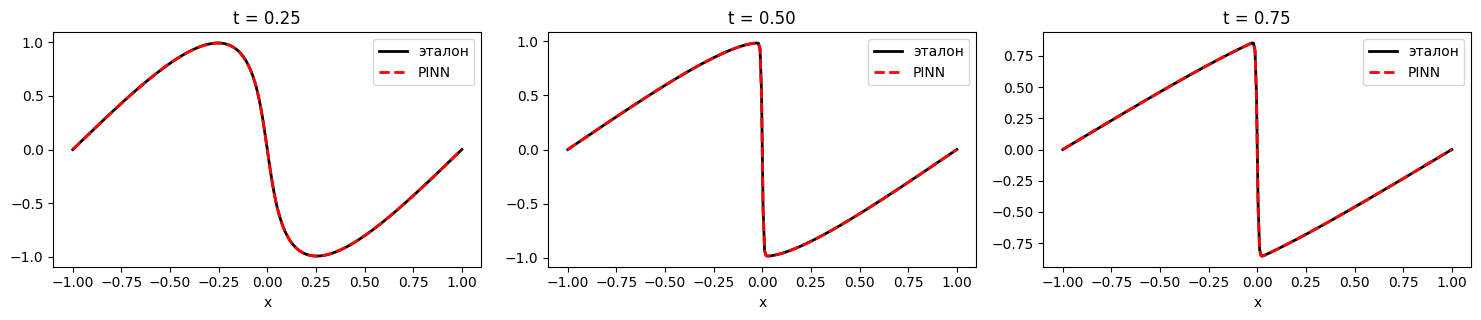

In [7]:
U_pred = u_pred.reshape(xx.shape)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, Z, title, cmap in [(axs[0], exact, "Эталон u(x,t)", "RdBu_r"),
                           (axs[1], U_pred, "PINN u(x,t)", "RdBu_r"),
                           (axs[2], np.abs(U_pred - exact), "|ошибка|", "viridis")]:
    im = ax.pcolormesh(tt, xx, Z, cmap=cmap, shading="auto")
    ax.set_xlabel("t"); ax.set_ylabel("x"); ax.set_title(title); fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(15, 3.3))
for ax, tv in zip(axs, [0.25, 0.5, 0.75]):
    i = np.argmin(np.abs(t.ravel() - tv))
    ax.plot(x, exact[i], "k-", lw=2, label="эталон")
    ax.plot(x, U_pred[i], "r--", lw=2, label="PINN")
    ax.set_title(f"t = {t.ravel()[i]:.2f}"); ax.set_xlabel("x"); ax.legend()
plt.tight_layout(); plt.show()

**Вывод.** Сеть восстанавливает решение по одному только уравнению и условиям, без данных внутри области. Ошибка сосредоточена у крутого фронта при $x\approx0$: там производные велики, и случайных точек коллокации не хватает, чтобы его разрешить. Для таких случаев в DeepXDE есть адаптивное добавление точек (пример `Burgers_RAR.py`).

---
## 3. Обратная задача: определение коэффициента диффузии

Уравнение диффузии с источником и **неизвестным** коэффициентом $C$:
$$u_t = C\,u_{xx} - e^{-t}\left(\sin\pi x - \pi^2\sin\pi x\right),\qquad x\in[-1,1],\ t\in[0,1].$$

Точное решение $u = \sin(\pi x)\,e^{-t}$ при **истинном $C = 1$**. Проверка: $u_t = -u$, $u_{xx}=-\pi^2 u$, и всё сокращается.

**Постановка обратной задачи:** $C$ неизвестен (стартуем с $C=2$). Зато известны начальное и граничные условия и **10 измерений** $u$ в момент $t=1$. Нужно найти одновременно $u(x,t)$ и $C$.

### 3.1 Неизвестный параметр как обучаемая переменная
`dde.Variable(2.0)` создаёт скалярный параметр (в PyTorch это `torch.nn.Parameter`). Он входит в невязку PDE, поэтому градиент потерь по нему ненулевой, и оптимизатор сдвигает $C$ туда, где уравнение согласуется с данными.

In [8]:
C = dde.Variable(2.0)    # начальное приближение; истинное значение 1.0

def diffusion_pde(x, y):
    dy_t = dde.grad.jacobian(y, x, i=0, j=1)
    dy_xx = dde.grad.hessian(y, x, i=0, j=0)
    return (dy_t - C * dy_xx
            + torch.exp(-x[:, 1:]) * (torch.sin(np.pi * x[:, 0:1]) - np.pi**2 * torch.sin(np.pi * x[:, 0:1])))

def exact_solution(x):
    return np.sin(np.pi * x[:, 0:1]) * np.exp(-x[:, 1:])

### 3.2 Условия и наблюдения
* `DirichletBC` и `IC` берут значения из точного решения.
* `PointSetBC` — **наблюдения**: 10 точек при $t=1$. Это ещё одно слагаемое потерь $\frac1{10}\sum|u_\theta - u_{obs}|^2$.
* `anchors=observe_x` добавляет точки наблюдений и в точки коллокации PDE.
* Точек коллокации намеренно мало (40 + 20 + 10): задача гладкая.
* `solution=` нужен только для метрики (L2-ошибка на 10 000 тестовых точек) и в обучении не участвует.

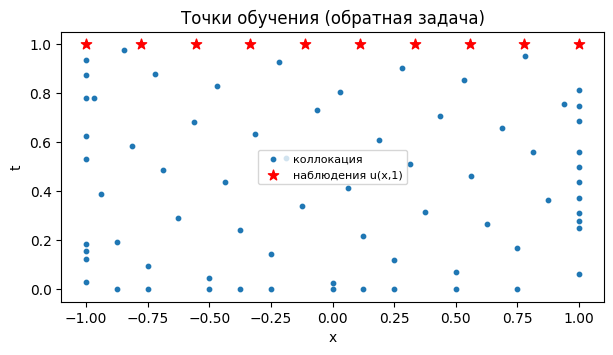

In [9]:
geom = dde.geometry.Interval(-1, 1)
timedomain = dde.geometry.TimeDomain(0, 1)
geomtime = dde.geometry.GeometryXTime(geom, timedomain)

bc = dde.icbc.DirichletBC(geomtime, exact_solution, lambda _, on_boundary: on_boundary)
ic = dde.icbc.IC(geomtime, exact_solution, lambda _, on_initial: on_initial)

observe_x = np.vstack((np.linspace(-1, 1, num=10), np.full(10, 1))).T
observe_y = dde.icbc.PointSetBC(observe_x, exact_solution(observe_x), component=0)

data_d = dde.data.TimePDE(geomtime, diffusion_pde, [bc, ic, observe_y],
                          num_domain=40, num_boundary=20, num_initial=10,
                          anchors=observe_x, solution=exact_solution, num_test=10000)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(data_d.train_x_all[:, 0], data_d.train_x_all[:, 1], s=10, label="коллокация")
ax.scatter(observe_x[:, 0], observe_x[:, 1], s=60, marker="*", c="r", label="наблюдения u(x,1)")
ax.set_xlabel("x"); ax.set_ylabel("t"); ax.set_title("Точки обучения (обратная задача)"); ax.legend(fontsize=8)
plt.show()

### 3.3 Обучение
`external_trainable_variables=C` передаёт параметр оптимизатору вместе с весами сети. Колбэк `VariableValue` каждые 1000 итераций записывает текущее $C$ в файл.

Столбцы потерь: **[PDE, BC, IC, наблюдения]**; последний столбец лога — L2-ошибка на тесте.

In [10]:
net_d = dde.nn.FNN([2] + [32] * 3 + [1], "tanh", "Glorot uniform")
model_d = dde.Model(data_d, net_d)
model_d.compile("adam", lr=0.001, metrics=["l2 relative error"], external_trainable_variables=C)

var_cb = dde.callbacks.VariableValue(C, period=1000, filename="variables_C.dat")
loss_d, state_d = model_d.train(iterations=50000, callbacks=[var_cb], display_every=5000)
print(f"\nНайденный C = {C.item():.5f}  (истинное 1.0, ошибка {abs(C.item() - 1) * 100:.3f}%)")

Compiling model...
'compile' took 0.000194 s



Training model...



Step      Train loss                                  Test loss                                   Test metric   


0         [1.41e+01, 7.58e-02, 3.77e-01, 7.57e-02]    [1.64e+01, 7.58e-02, 3.77e-01, 7.57e-02]    [8.37e-01]    


5000      [2.63e-04, 8.64e-05, 5.45e-06, 3.51e-05]    [4.05e-04, 8.64e-05, 5.45e-06, 3.51e-05]    [1.98e-02]    


...

40000     [2.85e-04, 1.56e-05, 1.69e-06, 7.51e-06]    [2.63e-04, 1.56e-05, 1.69e-06, 7.51e-06]    [5.24e-03]    


45000     [1.15e-04, 6.99e-06, 1.83e-06, 2.72e-06]    [1.02e-04, 6.99e-06, 1.83e-06, 2.72e-06]    [3.11e-03]    


50000     [1.38e-04, 7.62e-06, 2.04e-06, 2.82e-06]    [1.14e-04, 7.62e-06, 2.04e-06, 2.82e-06]    [3.06e-03]    



Best model at step 25000:
  train loss: 1.56e-05
  test loss: 4.28e-05
  test metric: [2.69e-03]

'train' took 267.761665 s




Найденный C = 0.99771  (истинное 1.0, ошибка 0.229%)


### 3.4 Результаты

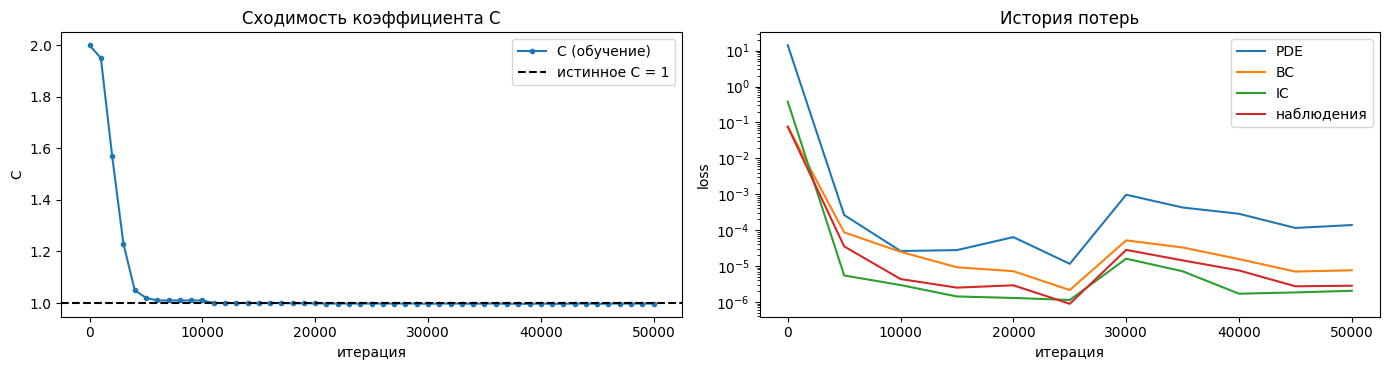

In [11]:
hist = np.loadtxt("variables_C.dat", converters={1: lambda s: float(s.strip("[]"))})
steps = np.array(loss_d.steps); lt = np.array(loss_d.loss_train)

fig, axs = plt.subplots(1, 2, figsize=(14, 3.8))
axs[0].plot(hist[:, 0], hist[:, 1], "o-", ms=3, label="C (обучение)")
axs[0].axhline(1.0, color="k", ls="--", label="истинное C = 1")
axs[0].set_xlabel("итерация"); axs[0].set_ylabel("C"); axs[0].set_title("Сходимость коэффициента C"); axs[0].legend()
for k, name in enumerate(["PDE", "BC", "IC", "наблюдения"]):
    axs[1].semilogy(steps, lt[:, k], label=name)
axs[1].set_xlabel("итерация"); axs[1].set_ylabel("loss"); axs[1].set_title("История потерь"); axs[1].legend()
plt.tight_layout(); plt.show()

Относительная L2-ошибка u: 0.0030850131811746423


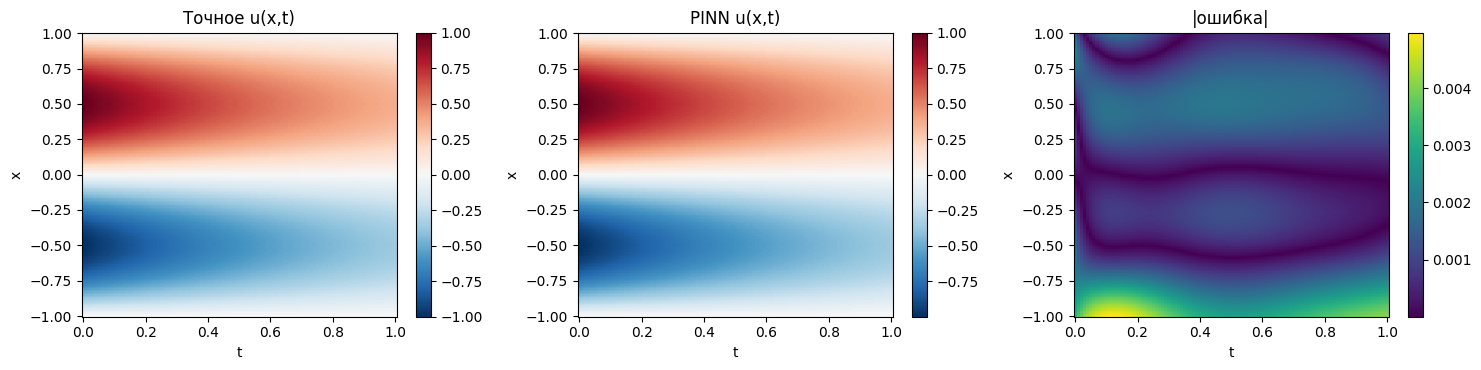

In [12]:
xs, ts = np.linspace(-1, 1, 201), np.linspace(0, 1, 101)
XX, TT = np.meshgrid(xs, ts)
Xg = np.vstack((XX.ravel(), TT.ravel())).T
U_true = exact_solution(Xg).reshape(XX.shape)
U_pred = model_d.predict(Xg).reshape(XX.shape)
print("Относительная L2-ошибка u:", dde.metrics.l2_relative_error(U_true, U_pred))

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, Z, title, cmap in [(axs[0], U_true, "Точное u(x,t)", "RdBu_r"),
                           (axs[1], U_pred, "PINN u(x,t)", "RdBu_r"),
                           (axs[2], np.abs(U_pred - U_true), "|ошибка|", "viridis")]:
    im = ax.pcolormesh(TT, XX, Z, cmap=cmap, shading="auto")
    ax.set_xlabel("t"); ax.set_ylabel("x"); ax.set_title(title); fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

**Вывод.** Начав с $C=2$, сеть за несколько тысяч итераций сводит коэффициент почти к истинному значению 1. Сработали только знание вида уравнения, начальные и граничные условия и 10 измерений в конечный момент. Одновременно восстанавливается всё поле $u(x,t)$.

---
## 4. Сравнение задач

| | Прямая (Бюргерс) | Обратная (диффузия) |
|---|---|---|
| Известно | уравнение целиком, IC, BC | вид уравнения, IC, BC, 10 измерений |
| Неизвестно | $u(x,t)$ | $u(x,t)$ **и** $C$ |
| Слагаемые потерь | PDE + BC + IC | PDE + BC + IC + данные |
| Обучаемые параметры | веса сети | веса сети + `dde.Variable` |
| Оптимизатор | Adam → L-BFGS | Adam |

С точки зрения кода между задачами всего две разницы: неизвестный параметр объявлен как `dde.Variable` и передан в `external_trainable_variables`, а наблюдения добавлены через `PointSetBC`. Остальной конвейер одинаковый.